## Description
This notebook generates visualizations and outputs them to results/visualisations to better understand how the model results come about. It is structured like:
1. Imports
2. Loading model runs
2. Setting technology colors for some visualisations
3. All functions
5. Inspecting results and using of functions for visualisations

### 1) Imports

In [41]:
from pathlib import Path
import re
import warnings
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import pypsa
from IPython.display import display

years = [2020, 2030, 2040, 2050]

### 2) Load networks

In [42]:
RESULTS_DIR = Path("results/temporal_scenarios")
SCENARIOS = ["default_tech_low_carbon", "default_tech_high_carbon", "improved_tech_low_carbon", "improved_tech_high_carbon"]
LABELS = {
    "default_tech_low_carbon": "Default technology | default CO₂ price",
    "default_tech_high_carbon": "Default technology | high CO₂ price",
    "improved_tech_low_carbon": "Improved technology | default CO₂ price",
    "improved_tech_high_carbon": "Improved technology | high CO₂ price",
}

networks = {}
for scenario in SCENARIOS:
    file = RESULTS_DIR / f"{scenario}.nc"
    if not file.exists():
        raise FileNotFoundError(f"Missing scenario result: {file}")
    networks[scenario] = pypsa.Network(str(file))

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'default_tech_low_carbon' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'default_tech_high_carbon' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'improved_tech_low_carbon' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'improved_tech_high_carbon' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks


### 3) Examining industrial low-to-medium heat demand provision

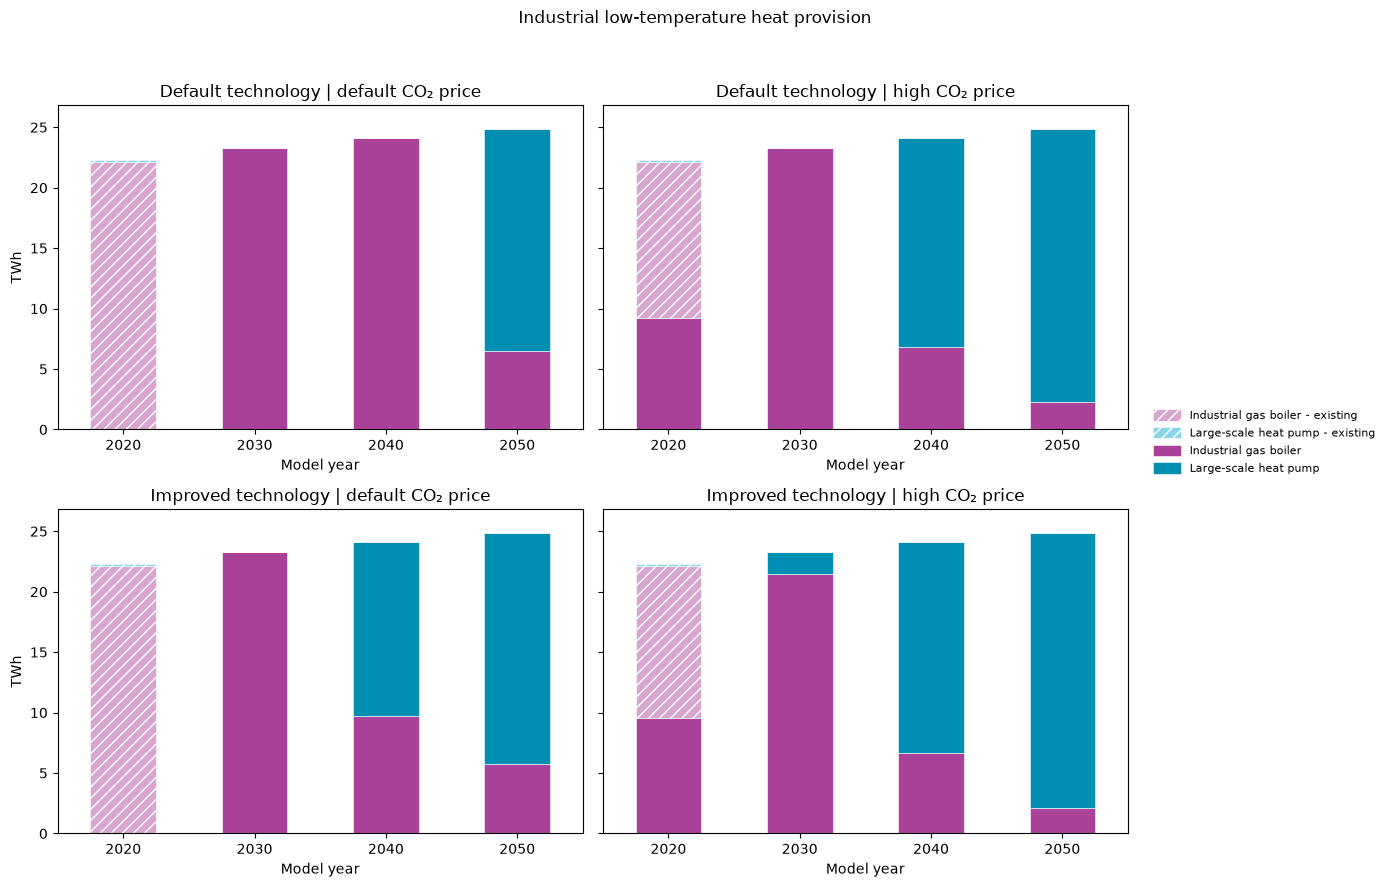

In [44]:
def plot_ltp_heat(networks, scenarios, labels, palette=None):
    """Extract annual LTP heat supply and plot four stacked-bar panels."""
    if len(scenarios) != 4:
        raise ValueError("Select exactly four scenarios for the 2×2 chart.")

    # Defaults reproduce the gas-boiler and heat-pump colour convention.
    colors = {
        "Industrial gas boiler": "#AA429A",
        "Industrial gas boiler - existing": "#D7A6CF",
        "Large-scale heat pump": "#008FB3",
        "Large-scale heat pump - existing": "#88D6E5",
    }
    tables = {}

    # 1. Extract heat output, weight by represented hours (t_res=7), and sum by year.
    for scenario in scenarios:
        n = networks[scenario]
        heat_buses = n.buses.index[
            n.buses["carrier"].eq("Industrial LTP")
            | n.buses.index.isin(["Industrial LTP"])
        ]
        carriers = n.links["carrier"].astype(str)
        base_carriers = carriers.str.replace(r" - existing$", "", regex=True)
        links = n.links.index[
            n.links["bus1"].isin(heat_buses)
            & base_carriers.isin([
                "Industrial gas boiler", "Large-scale heat pump"
            ])
        ]
        if links.empty:
            raise ValueError(f"No LTP boilers or heat pumps found in {scenario}.")

        # Delivery to bus1 is negative in PyPSA. MW × hours gives MWh.
        heat = (-n.links_t.p1.loc[:, links]).clip(lower=0).mul(
            n.snapshot_weightings["generators"], axis=0
        )
        heat = heat.T.groupby(carriers.loc[links]).sum().T

        if isinstance(n.snapshots, pd.MultiIndex):
            years = n.snapshots.get_level_values(0)
        elif isinstance(n.snapshots, pd.DatetimeIndex):
            years = n.snapshots.year
        else:
            raise ValueError("Expected multi-period or datetime snapshots.")

        tables[scenario] = heat.groupby(years).sum() / 1e6  # MWh → TWh

    # 2. Use the same technologies, year positions, and y-axis in every panel.
    technologies = sorted({
        c for table in tables.values() for c in table.columns
        if table[c].abs().max() > 1e-8
    })
    if not technologies:
        raise ValueError("No nonzero LTP heat supply to plot.")

    years = sorted({year for table in tables.values() for year in table.index})
    max_supply = max(table.sum(axis=1).max() for table in tables.values())
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)

    for ax, scenario in zip(axes.flat, scenarios):
        table = tables[scenario].reindex(
            index=years, columns=technologies
        ).fillna(0)
        table.plot.bar(
            stacked=True, ax=ax, rot=0, legend=False,
            color=[colors.get(c, "#B0B5BC") for c in technologies],
            edgecolor="white", linewidth=0.4,
        )
        for technology, container in zip(technologies, ax.containers):
            if technology.endswith(" - existing"):
                for bar in container:
                    bar.set_hatch("///")

        ax.set_title(labels[scenario])
        ax.set_xlabel("Model year")
        ax.set_ylabel("TWh")
        ax.set_ylim(0, max_supply * 1.08)  # added so the 2050 bar does not touch the top
        ax.grid(False)

    # 3. Add one shared legend, with existing technologies listed first.
    legend_order = sorted(
        technologies,
        key=lambda c: (not c.endswith(" - existing"), c.lower()),
    )
    fig.legend(
        handles=[
            Patch(
                facecolor=colors.get(c, "#B0B5BC"), edgecolor="white",
                linewidth=0.4,
                hatch="///" if c.endswith(" - existing") else None,
                label=c,
            )
            for c in legend_order
        ],
        loc="center left", bbox_to_anchor=(0.82, 0.5),
        frameon=False, fontsize=8, handlelength=2.5, handleheight=1.2,
    )
    fig.suptitle("Industrial low-temperature heat provision")
    fig.tight_layout(rect=[0, 0, 0.82, 0.95])
    plt.show()
    return fig, axes


# Reuse the loaded networks and scenario labels; produce the chart.
fig, axes = plot_ltp_heat(networks, SCENARIOS, LABELS)

In [ ]:
# Handy plotting functions. 
# Note that these are good to quickly diagnose your runs, 
# but for your final presentation and paper you will need
# nicer-looking plots, following the data-visualization 
# guidelines we discussed in class!

def plot_main_ebs(scen):
    fig, ax = plt.subplots(1, 1)
    fig.set_size_inches(10, 4)

    df = scen.statistics.energy_balance(bus_carrier='Hydrogen')
    df = df.set_index(df.index.get_level_values(1)).T
    df.plot(kind='bar', stacked='True', rot=0, colormap="tab20", ax=ax)
    ax.set_ylabel('MWh')
    ax.set_title(scen.name)

    fig.tight_layout()

def plot_main_ebs_complete(scen):
    fig, ax = plt.subplots(1,5)
    fig.set_size_inches(20,4)

    for n,c in enumerate(['Residential electricity',
            'Residential heat',
            'Transportation',
            'Industrial machinery',
            'Industrial HTP']): 
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1)).T
        df.plot(kind='bar',stacked='True', rot=0, colormap="tab20",ax=ax[n])
        if c=='Transportation':
            ax[n].set_ylabel('Mvkm')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)

    fig.tight_layout()

def plot_elc_emi(scen):
    fig, ax = plt.subplots(1,5)
    fig.set_size_inches(20,4)

    for n,c in enumerate(['Electricity','CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1)).T
        df.plot(kind='bar',stacked='True', rot=0, colormap="tab20", ax=ax[n])

        if 'CO2' in c:
            ax[n].set_ylabel('tCO2')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)
        ax[n].legend(bbox_to_anchor=(1,-0.5))

    # Let's add cumulative CO2
    for n,c in enumerate(['CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c).cumsum(axis=1)
        df = df.set_index(df.index.get_level_values(1))
        df.T.plot(kind='bar', stacked=True, colormap='tab20', ax=ax[n+3])
        ax[n+3].set_ylabel('tCO2')
        ax[n+3].set_title(f'Cumulative {c}')
        ax[n+3].legend(bbox_to_anchor=(1,-0.5))

    fig.tight_layout()


In [ ]:
def heatpump_metrics(n):
    """Active output capacity, annual heat, and annual electricity input.

    Assumes the heat pump is a Link with electricity at bus0 and useful
    heat at bus1, as in the model's two-bus Link implementation.
    Includes active older investment vintages, not just new builds.
    """
    if not isinstance(n.snapshots, pd.MultiIndex):
        raise ValueError("Expected multi-period snapshots (period, timestamp).")

    hp = n.links.index[n.links["carrier"].eq("Large-scale heat pump")]
    if len(hp) == 0:
        raise ValueError(f"No large-scale heat-pump Links found in {n.name}.")

    missing = hp.difference(n.links_t.p0.columns).union(
        hp.difference(n.links_t.p1.columns)
    )
    if len(missing):
        raise ValueError(f"Missing optimized heat-pump dispatch: {list(missing)}")

    periods = list(n.investment_periods)
    result = pd.DataFrame(
        index=pd.Index(periods, name="Model year"),
        columns=["Heat capacity (GWth)", "Heat output (TWh/year)",
                 "Electricity input (TWh/year)"],
        dtype=float,
    )

    for year in periods:
        # Link p_nom is input capacity. Multiply by COP/efficiency to obtain
        # heat-output capacity. Do not sum expired or future vintages.
        active_mask = (
            n.links.loc[hp, "build_year"].le(year)
            & (n.links.loc[hp, "build_year"] + n.links.loc[hp, "lifetime"]).gt(year)
        )
        active = hp[active_mask.to_numpy()]
        result.loc[year, "Heat capacity (GWth)"] = (
            n.links.loc[active, "p_nom_opt"]
            * n.links.loc[active, "efficiency"]
        ).sum() / 1e3

        snapshots = n.snapshots[n.snapshots.get_level_values(0) == year]
        # These weights account for the hours represented by each snapshot.
        # Do not multiply by the decade's investment-period weighting here:
        # the result is annual energy, not total energy over the whole decade.
        weights = n.snapshot_weightings.loc[snapshots, "generators"]
        heat = -n.links_t.p1.loc[snapshots, hp].sum(axis=1)
        electricity = n.links_t.p0.loc[snapshots, hp].sum(axis=1)
        result.loc[year, "Heat output (TWh/year)"] = heat.mul(weights).sum() / 1e6
        result.loc[year, "Electricity input (TWh/year)"] = (
            electricity.mul(weights).sum() / 1e6
        )

    return result


metrics = {scenario: heatpump_metrics(n) for scenario, n in networks.items()}

# FIGURE 1: Direct comparison of the heat-pump results.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metric in zip(axes, next(iter(metrics.values())).columns):
    for scenario in SCENARIOS:
        ax.plot(
            metrics[scenario].index,
            metrics[scenario][metric],
            label=LABELS[scenario],
            color=COLORS[scenario],
            linestyle="--" if scenario.endswith("high") else "-",
            marker="o",
        )
    ax.set_title(metric.split(" (")[0])
    ax.set_ylabel(metric.split("(")[1].rstrip(")"))
    ax.set_xlabel("Model year")
    ax.set_xticks(next(iter(metrics.values())).index)
    ax.grid(axis="y", alpha=0.25)
    ax.set_ylim(bottom=0)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
fig.suptitle("Large-scale heat pumps: scenario comparison")
fig.tight_layout(rect=[0, 0.16, 1, 0.94])
plt.show()


def plot_energy_balance_comparison(bus_carrier="Electricity", unit="TWh"):
    """Four stacked energy balances, adapted from the supplied functions.

    Positive bars are injections into the selected bus carrier;
    negative bars are withdrawals. Values use PyPSA's statistics aggregation.
    Suitable for energy carriers; use unit='tCO2' for emissions carriers.
    """
    if unit not in {"TWh", "MWh", "tCO2"}:
        raise ValueError("Choose TWh, MWh, or tCO2.")
    scale = 1e6 if unit == "TWh" else 1.0
    balances = {}
    for scenario, n in networks.items():
        df = n.statistics.energy_balance(bus_carrier=bus_carrier)
        if not isinstance(df, pd.DataFrame):
            raise ValueError("Expected statistics columns to represent model years.")
        if not set(n.investment_periods).issubset(df.columns):
            raise ValueError(f"Unexpected statistics columns: {list(df.columns)}")
        if df.empty:
            raise ValueError(f"No energy balance found for {bus_carrier!r}.")
        # Aggregate duplicate carriers rather than simply relabelling rows.
        if isinstance(df.index, pd.MultiIndex):
            level = "carrier" if "carrier" in df.index.names else 1
            df = df.groupby(level=level).sum()
        else:
            df = df.groupby(level=0).sum()
        balances[scenario] = df.loc[:, list(n.investment_periods)].T / scale

    carriers = sorted(set().union(*(set(df.columns) for df in balances.values())))
    # Retrieve carrier colors from your tech_colors dictionary.
    # Use neutral grey for carriers without a defined color.
    colors = {c: tech_colors.get(c, "#B0B5BC") for c in carriers}
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)
    for ax, scenario in zip(axes.flat, SCENARIOS):
        df = balances[scenario].reindex(columns=carriers, fill_value=0).fillna(0)
        df.plot.bar(
            stacked=True,
            rot=0,
            ax=ax,
            color=[colors[c] for c in carriers],
            edgecolor="white",
            linewidth=0.4,
            legend=False,
        )
        # Each container corresponds to one carrier in the stacked bar chart.
        for carrier, container in zip(carriers, ax.containers):
            if carrier.endswith(" - existing"):
                for bar in container:
                    bar.set_hatch("///")
        ax.axhline(0, color="black", linewidth=0.7)
        ax.set_title(LABELS[scenario])
        ax.set_ylabel(unit)
        ax.set_xlabel("Model year")
        ax.grid(False)
        handles, labels = axes.flat[0].get_legend_handles_labels()

        # Existing technologies first; alphabetical order within each group.
        legend_items = sorted(
            zip(handles, labels),
            key=lambda item: (
                not item[1].endswith(" - existing"),
                item[1].lower(),),)

        sorted_handles, sorted_labels = zip(*legend_items)

        fig.legend( sorted_handles, sorted_labels, loc="center left", bbox_to_anchor=(0.82, 0.5), 
                   frameon=False,
                    fontsize=8,)
        
    fig.suptitle(f"{bus_carrier}: injections (+) and withdrawals (−)")
    fig.tight_layout(rect=[0, 0, 0.82, 0.95])
    plt.show()


# FIGURE 2: Electricity balances for all four scenarios.
plot_energy_balance_comparison("Electricity", unit="TWh")

# Optional: uncomment ONE of these to inspect another balance.
# Use exact bus-carrier names from your input database.
# plot_energy_balance_comparison("Residential heat", unit="TWh")
plot_energy_balance_comparison("Industrial LTP", unit="TWh")
# plot_energy_balance_comparison("Hydrogen", unit="TWh")
plot_energy_balance_comparison("CO2 atmosphere", unit="tCO2")